# Exploratory analysis and offline results

This notebook covers two things:

1. **The data.** What the 10,000-user, 5,000-movie MovieLens sample looks like, and why it was chosen.
2. **The results.** How the recommenders compare in the offline evaluation.

It reads only the small processed files (`data/processed/`, about 30 MB) and `reports/evaluation.json`. You can
run it end to end in a few seconds on a laptop. Produce those inputs first:

```bash
python manage.py prepare_data && python manage.py evaluate_recommenders
```

The figures are also saved to `reports/figures/` so the README can show them. MovieLens may not be
redistributed, so this notebook prints only aggregates and well-known movie titles, never raw rating rows.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / 'manage.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from system.ml.data import POSITIVE_THRESHOLD, load_dataset, temporal_split  # noqa: E402
from system.ml.moods import MOOD_TAGS  # noqa: E402

PROCESSED, FIGURES = ROOT / 'data' / 'processed', ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
MOOD_THRESHOLD = 0.5  # settings.MOOD_THRESHOLD: a movie gets a mood when its score is at least this

# One visual system for every chart: thin marks, hairline grid, text in ink colours rather than series colours.
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
BLUE, ORANGE, NEUTRAL = '#2a78d6', '#eb6834', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'legend.frameon': False,
})


def save(fig, name):
    fig.savefig(FIGURES / f'{name}.png')
    plt.show()

## 1. The data

In [2]:
manifest = json.loads((PROCESSED / 'manifest.json').read_text())
q = manifest['quality']
catalog = pd.read_csv(PROCESSED / 'catalog.csv')
ds = load_dataset(PROCESSED)

pd.Series({
    'MovieLens 25M ratings scanned': f"{q['ratings_total']:,}",
    'movies with any rating': f"{q['movies_with_ratings']:,}",
    'movies with Tag Genome scores': f"{q['movies_with_genome']:,}",
    'catalog (most-rated genome movies)': f"{q['catalog_movies']:,}",
    'share of all ratings the catalog covers': f"{q['catalog_share_of_all_ratings']:.1%}",
    'sampled users (>= 20 ratings in the catalog)': f"{q['users']['sampled_users']:,}",
    'interactions kept': f"{q['interactions']:,}",
    'matrix density': f"{q['density']:.1%}",
    'rating period': ' to '.join(q['timestamp_range']),
}, name='value').to_frame()

,value
MovieLens 25M ratings scanned,"25,000,095"
movies with any rating,"59,047"
movies with Tag Genome scores,"13,816"
catalog (most-rated genome movies),"5,000"
share of all ratings the catalog covers,92.2%
sampled users (>= 20 ratings in the catalog),"10,000"
interactions kept,"1,450,162"
matrix density,2.9%
rating period,1996-02-19 to 2019-11-21


### 1.1 The long tail and why 5,000 movies is enough

Ratings are extremely concentrated. The catalog keeps the 5,000 most-rated movies that have Tag Genome
scores: 8% of the rated movies, but 92% of all ratings. Most of the movies left out have only a handful of ratings,
too few for collaborative filtering to learn anything about them. Dropping them shrinks every matrix more than
tenfold at little cost.

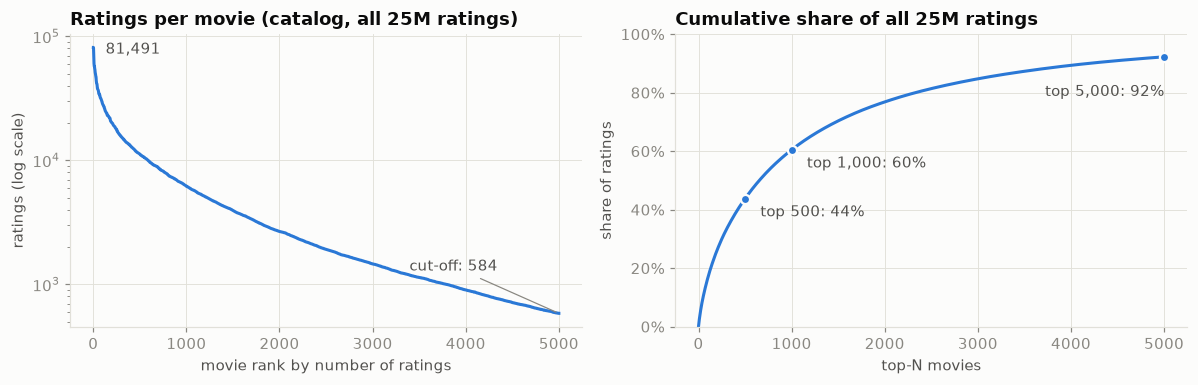

In [3]:
counts = np.sort(catalog['ml_rating_count'].to_numpy())[::-1]
share = np.cumsum(counts) / q['ratings_total']

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.plot(np.arange(1, len(counts) + 1), counts, color=BLUE)
a.set_yscale('log')
a.set(title='Ratings per movie (catalog, all 25M ratings)', xlabel='movie rank by number of ratings',
      ylabel='ratings (log scale)')
a.annotate(f'{counts[0]:,}', (1, counts[0]), xytext=(8, -4), textcoords='offset points', color=INK2)
a.annotate(f'cut-off: {counts[-1]:,}', (len(counts), counts[-1]), xytext=(-40, 28), textcoords='offset points',
           ha='right', color=INK2, arrowprops={'arrowstyle': '-', 'color': MUTED, 'linewidth': 0.8})

b.plot(np.arange(1, len(counts) + 1), share, color=BLUE)
b.set(title='Cumulative share of all 25M ratings', xlabel='top-N movies', ylabel='share of ratings', ylim=(0, 1))
b.yaxis.set_major_formatter('{x:.0%}')
for n, offset, ha in ((500, (10, -4), 'left'), (1000, (10, -4), 'left'), (5000, (0, -18), 'right')):
    b.plot(n, share[n - 1], 'o', color=BLUE, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    b.annotate(f'top {n:,}: {share[n - 1]:.0%}', (n, share[n - 1]), xytext=offset, textcoords='offset points',
               ha=ha, va='top', color=INK2)
fig.tight_layout()
save(fig, 'long_tail')

### 1.2 Users: activity, ratings and what counts as a "like"

Users were sampled with a fixed seed from a pool of eligible users who have at least 20 ratings in the catalog,
so the sample is reproducible and the sampling rule is easy to state. Activity still spans two orders of magnitude.
Ratings are skewed upwards, and the threshold of 4 stars or more turns about half of them into positive implicit
feedback. The models learn only from these likes; a rating of 3 means "watched, not loved".

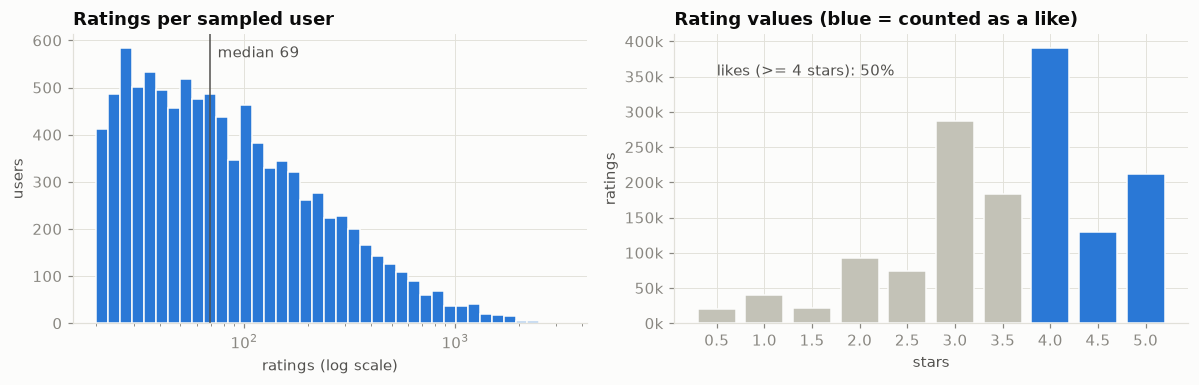

ratings per user: min 20, median 69, 90th pct 339, max 3261


In [4]:
per_user = np.bincount(ds.users)
dist = pd.Series(q['rating_distribution']).rename(index=float).sort_index()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 40)
a.hist(per_user, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
a.set_xscale('log')
a.set(title='Ratings per sampled user', xlabel='ratings (log scale)', ylabel='users')
med = np.median(per_user)
a.axvline(med, color=INK2, linewidth=1)
a.annotate(f'median {med:.0f}', (med, a.get_ylim()[1] * 0.92), xytext=(5, 0), textcoords='offset points', color=INK2)

colors = [BLUE if r >= POSITIVE_THRESHOLD else NEUTRAL for r in dist.index]
b.bar(dist.index.astype(str), dist.to_numpy(), color=colors, edgecolor=SURFACE, linewidth=1)
b.set(title='Rating values (blue = counted as a like)', xlabel='stars', ylabel='ratings')
b.yaxis.set_major_formatter(lambda x, _: f'{x / 1e3:.0f}k')
pos_share = dist[dist.index >= POSITIVE_THRESHOLD].sum() / dist.sum()
b.annotate(f'likes (>= {POSITIVE_THRESHOLD:g} stars): {pos_share:.0%}', (0, dist.max() * 0.9), color=INK2)
fig.tight_layout()
save(fig, 'users_and_ratings')

print(f'ratings per user: min {per_user.min()}, median {med:.0f}, 90th pct {np.percentile(per_user, 90):.0f}, '
      f'max {per_user.max()}')

### 1.3 Time

The evaluation splits **each user's own history** chronologically: their newest 20% is test, the 10% before
that is validation, and the rest is training. Rating activity is bursty over 1996–2019, and the films are mostly from
the 1990s and 2000s. Because the cut is per user, the folds have no single global cut-off date. That is one of the
caveats listed in the README, and section 2 comes back to it.

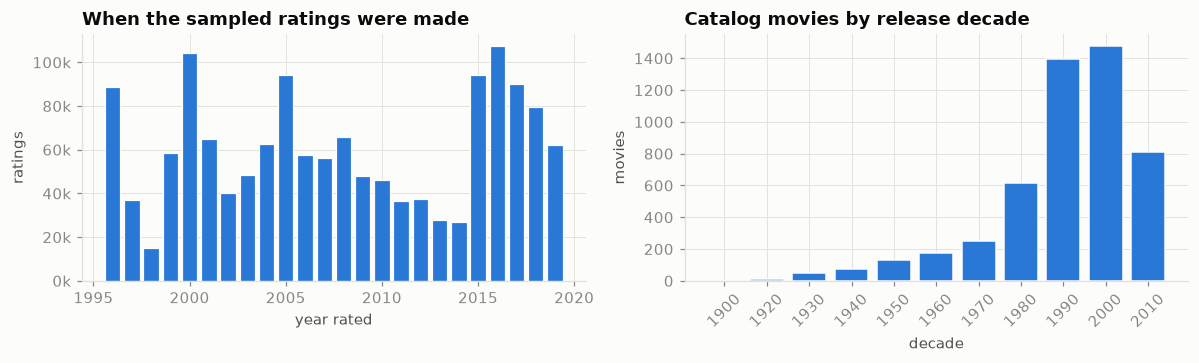

years between release and rating: median 10, 12% of ratings within a year of release


In [5]:
rated = pd.to_datetime(ds.timestamps, unit='s').year
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
yr = pd.Series(rated).value_counts().sort_index()
a.bar(yr.index, yr.to_numpy(), color=BLUE, edgecolor=SURFACE, linewidth=0.8)
a.set(title='When the sampled ratings were made', xlabel='year rated', ylabel='ratings')
a.yaxis.set_major_formatter(lambda x, _: f'{x / 1e3:.0f}k')

decade = (catalog['year'].dropna() // 10 * 10).astype(int).value_counts().sort_index()
b.bar(decade.index.astype(str), decade.to_numpy(), color=BLUE, edgecolor=SURFACE, linewidth=1)
b.set(title='Catalog movies by release decade', xlabel='decade', ylabel='movies')
b.tick_params(axis='x', rotation=45)
fig.tight_layout()
save(fig, 'time')

gap = rated - catalog['year'].to_numpy()[ds.items]
print(f'years between release and rating: median {np.nanmedian(gap):.0f}, '
      f'{np.nanmean(gap <= 1):.0%} of ratings within a year of release')

### 1.4 Genres and Tag Genome moods

Genres are coarse: the median film has two, and "Drama" alone covers almost half the catalog. The app's **moods**
come from the Tag Genome instead. The Genome is a published model that scores 1,128 tags for every movie from user
tags, ratings and reviews. Each mood is the mean relevance of a few hand-picked tags (`system/ml/moods.py`), and a movie
gets a mood when that mean is at least 0.5.

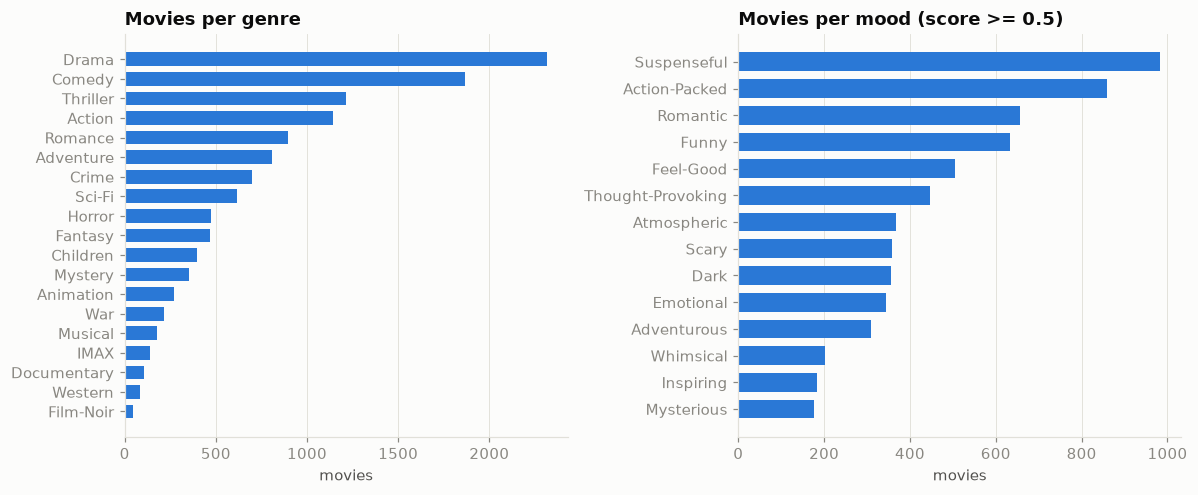

genres per movie: median 2; moods per movie: median 1, 28% of movies have none


In [6]:
genres = catalog['genres'].str.split('|').explode()
genres = genres[genres != '(no genres listed)'].value_counts()

moods = np.load(PROCESSED / 'mood_scores.npy')
mood_names = list(MOOD_TAGS)
mood_counts = pd.Series((moods >= MOOD_THRESHOLD).sum(axis=0), index=mood_names).sort_values()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6))
g = genres.sort_values()
a.barh(g.index, g.to_numpy(), color=BLUE, height=0.7)
a.set(title='Movies per genre', xlabel='movies')
a.grid(axis='y', visible=False)
b.barh(mood_counts.index, mood_counts.to_numpy(), color=BLUE, height=0.7)
b.set(title=f'Movies per mood (score >= {MOOD_THRESHOLD})', xlabel='movies')
b.grid(axis='y', visible=False)
fig.tight_layout()
save(fig, 'genres_and_moods')

print(f'genres per movie: median {catalog.genres.str.count("[|]").add(1).median():.0f}; '
      f'moods per movie: median {np.median((moods >= MOOD_THRESHOLD).sum(1)):.0f}, '
      f'{((moods >= MOOD_THRESHOLD).sum(1) == 0).mean():.0%} of movies have none')

A quick sanity check: the highest-scoring films for each mood should be the ones a film fan would expect.

In [7]:
top = {m: ', '.join(f"{catalog.title[i]} ({catalog.year[i]:.0f})" for i in np.argsort(-moods[:, j])[:3])
       for j, m in enumerate(mood_names)}
pd.set_option('display.max_colwidth', None)
pd.Series(top, name='top 3 movies by mood score').to_frame()

,top 3 movies by mood score
Funny,"Austin Powers: International Man of Mystery (1997), Austin Powers: The Spy Who Shagged Me (1999), Wayne's World (1992)"
Feel-Good,"Jerry Maguire (1996), Love Actually (2003), The Blind Side (2009)"
Romantic,"You've Got Mail (1998), The Notebook (2004), Sleepless in Seattle (1993)"
Dark,"The Machinist (2004), Requiem for a Dream (2000), We Need to Talk About Kevin (2011)"
Scary,"Mama (2013), Insidious (2010), Candyman (1992)"
Suspenseful,"The Silence of the Lambs (1991), Don't Breathe (2016), 10 Cloverfield Lane (2016)"
Action-Packed,"The Bourne Ultimatum (2007), Crank (2006), The Bourne Identity (2002)"
Adventurous,"The Hobbit: An Unexpected Journey (2012), The Hobbit: The Desolation of Smaug (2013), The Lord of the Rings: The Fellowship of the Ring (2001)"
Thought-Provoking,"Ex Machina (2015), Waking Life (2001), Fight Club (1999)"
Emotional,"The Pursuit of Happyness (2006), Life Is Beautiful (La Vita è bella) (1997), Awakenings (1990)"


Moods are not independent. The heatmap shows which ones go together and which are near opposites. That is why
the recommender treats a mood as a *filter* on candidates, not as a one-hot class.

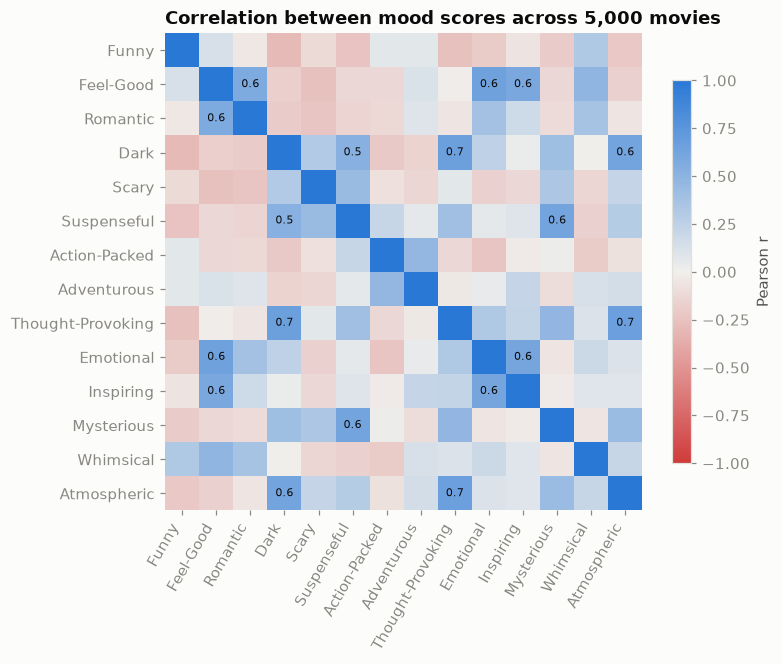

most opposite: Funny / Dark (-0.30), Funny / Thought-Provoking (-0.25), Feel-Good / Scary (-0.25)
most alike:    Thought-Provoking / Atmospheric (0.67), Dark / Thought-Provoking (0.66), Feel-Good / Emotional (0.64)


In [8]:
corr = np.corrcoef(moods.T)
cmap = LinearSegmentedColormap.from_list('div', ['#d03b3b', '#f0efec', BLUE])  # red <- gray -> blue
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(mood_names)), mood_names, rotation=60, ha='right')
ax.set_yticks(range(len(mood_names)), mood_names)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(mood_names)):
    for j in range(len(mood_names)):
        if i != j and abs(corr[i, j]) >= 0.5:
            ax.text(j, i, f'{corr[i, j]:.1f}', ha='center', va='center', fontsize=7,
                    color=SURFACE if abs(corr[i, j]) > 0.7 else INK)
ax.set_title('Correlation between mood scores across 5,000 movies')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
fig.tight_layout()
save(fig, 'mood_correlation')

pairs = [(corr[i, j], mood_names[i], mood_names[j]) for i in range(len(corr)) for j in range(i + 1, len(corr))]
pairs.sort()
print('most opposite:', ', '.join(f'{a} / {b} ({r:.2f})' for r, a, b in pairs[:3]))
print('most alike:   ', ', '.join(f'{a} / {b} ({r:.2f})' for r, a, b in pairs[-3:][::-1]))

### 1.5 The evaluation split

The split is chronological within each user's history. When several interactions share the timestamp at a
boundary, they all go to the later fold, so no fold contains anything newer than the fold after it.

In [9]:
fold = temporal_split(ds.users, ds.timestamps, val_frac=0.1, test_frac=0.2)
likes = ds.ratings >= POSITIVE_THRESHOLD
pd.DataFrame({
    'interactions': np.bincount(fold, minlength=3),
    'likes': np.bincount(fold[likes], minlength=3),
}, index=['train', 'validation', 'test']).assign(share=lambda d: (d.interactions / d.interactions.sum()).round(3))

,interactions,likes,share
train,1001576,517877,0.691
validation,149876,71153,0.103
test,298710,142155,0.206


## 2. Offline results

Hyperparameters were tuned on the validation fold. Each tuned model was then refit on train plus validation and scored
**once** on the test fold. The metric is NDCG@10 over each user's test likes, with bootstrap 95% confidence
intervals. *Cold start* means the user's history is cut to their 3 most recent likes; this is done in the training
matrix itself, so no model ever sees the removed likes.

In [10]:
ev = json.loads((ROOT / 'reports' / 'evaluation.json').read_text())
MODELS = ['random', 'popularity', 'content', 'item_knn', 'als', 'hybrid']
LABELS = {'random': 'Random', 'popularity': 'Popularity', 'content': 'Content (genome)',
          'item_knn': 'Item-kNN', 'als': 'ALS', 'hybrid': 'Hybrid (served)'}

rows = []
for setting, key in (('full history', 'test_results'), ('cold start', 'test_results_cold_start')):
    for m in MODELS:
        r = ev[key][m]
        rows.append({'setting': setting, 'model': LABELS[m], 'ndcg@10': r['ndcg@10'],
                     'ci_low': r['ndcg@10_ci95'][0], 'ci_high': r['ndcg@10_ci95'][1],
                     'recall@10': r['recall@10'], 'coverage': r['coverage'], 'ild@10': r['ild@10'],
                     'popularity_pct': r['popularity_percentile@10']})
results = pd.DataFrame(rows)
results.pivot(index='model', columns='setting', values='ndcg@10').loc[[LABELS[m] for m in MODELS]].round(4)

setting,cold start,full history
model,,
Random,0.0034,0.0036
Popularity,0.0792,0.0790
Content (genome),0.0514,0.0582
Item-kNN,0.1107,0.1249
ALS,0.1171,0.1455
Hybrid (served),0.1187,0.1483


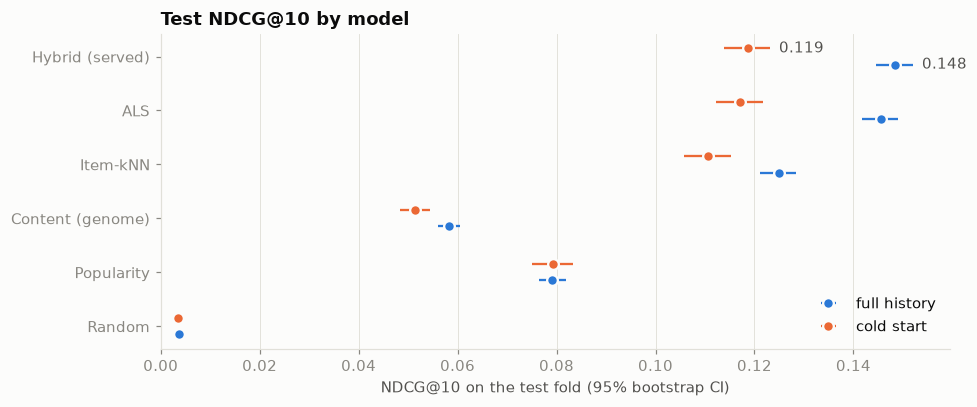

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(MODELS))
for offset, (setting, color) in zip((-0.15, 0.15), (('full history', BLUE), ('cold start', ORANGE))):
    d = results[results.setting == setting].set_index('model').loc[[LABELS[m] for m in MODELS]]
    ax.errorbar(d['ndcg@10'], y + offset, xerr=[d['ndcg@10'] - d.ci_low, d.ci_high - d['ndcg@10']], fmt='o',
                color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, elinewidth=1.5,
                capsize=0, label=setting)
    last = d.iloc[-1]
    ax.annotate(f"{last['ndcg@10']:.3f}", (last.ci_high, len(MODELS) - 1 + offset), xytext=(6, 0),
                textcoords='offset points', va='center', color=INK2)
ax.set_yticks(y, [LABELS[m] for m in MODELS])
ax.grid(axis='y', visible=False)
ax.set(xlabel='NDCG@10 on the test fold (95% bootstrap CI)', xlim=(0, None))
ax.set_title('Test NDCG@10 by model')
ax.legend(loc='lower right')
fig.tight_layout()
save(fig, 'ndcg_by_model')

**Reading it.** Every learned model beats the random baseline by a wide margin. The non-personalised
popularity baseline is strong: it beats content-only recommendations, which is typical for MovieLens. The two
collaborative models clearly beat popularity. With full histories, ALS beats item-kNN and the served hybrid adds a small
but significant gain on top of ALS. In the cold-start setting the gaps shrink and hybrid vs ALS is no longer
significant. There, the hybrid's real advantage is coverage (section 2.1).

The intervals above are per model. To compare two models you need *paired* differences, because the same users
are scored by both:

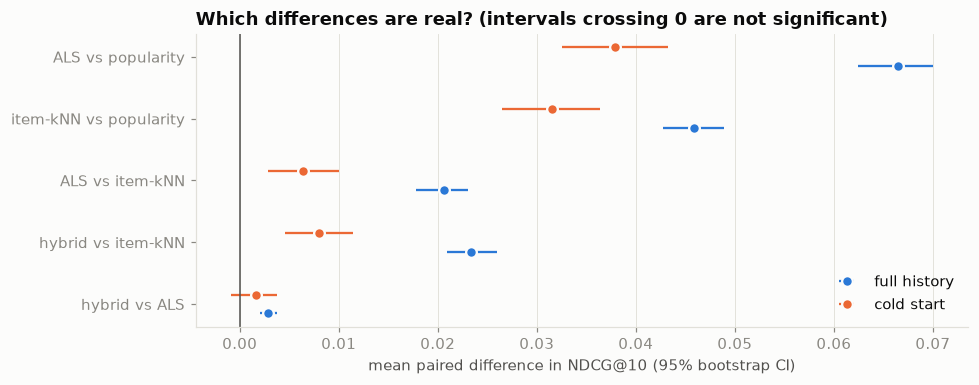

diff      lo      hi
comparison            setting                        
item_knn - popularity full     0.0459  0.0427  0.0489
                      cold     0.0315  0.0265  0.0364
als - popularity      full     0.0665  0.0624  0.0700
                      cold     0.0379  0.0325  0.0433
als - item_knn        full     0.0206  0.0178  0.0231
                      cold     0.0064  0.0029  0.0100
hybrid - als          full     0.0029  0.0020  0.0038
                      cold     0.0016 -0.0009  0.0038
hybrid - item_knn     full     0.0234  0.0209  0.0260
                      cold     0.0080  0.0046  0.0114

In [12]:
diffs = pd.DataFrame([{'comparison': k.rsplit(' (', 1)[0], 'setting': k.rsplit(' (', 1)[1].rstrip(')'),
                       'diff': v['mean_ndcg@10_diff'], 'lo': v['ci95'][0], 'hi': v['ci95'][1]}
                      for k, v in ev['paired_comparisons'].items()])
keep = ['hybrid - als', 'hybrid - item_knn', 'als - item_knn', 'item_knn - popularity', 'als - popularity']
diffs = diffs[diffs.comparison.isin(keep)]

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(keep))
for offset, (setting, color) in zip((-0.15, 0.15), (('full', BLUE), ('cold', ORANGE))):
    d = diffs[diffs.setting == setting].set_index('comparison').loc[keep]
    ax.errorbar(d['diff'], y + offset, xerr=[d['diff'] - d.lo, d.hi - d['diff']], fmt='o', color=color,
                markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, elinewidth=1.5, capsize=0,
                label={'full': 'full history', 'cold': 'cold start'}[setting])
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(y, [c.replace('item_knn', 'item-kNN').replace('als', 'ALS').replace(' - ', ' vs ') for c in keep])
ax.grid(axis='y', visible=False)
ax.set(xlabel='mean paired difference in NDCG@10 (95% bootstrap CI)')
ax.set_title('Which differences are real? (intervals crossing 0 are not significant)')
ax.legend(loc='lower right')
fig.tight_layout()
save(fig, 'paired_differences')

diffs.round(4).set_index(['comparison', 'setting'])

### 2.1 Beyond accuracy

Accuracy alone rewards recommending blockbusters. **Coverage** is the share of the catalog that appears in
anyone's top 10. **Popularity percentile** is how mainstream the recommended films are, where 1.0 means only the
most popular. **ILD** (intra-list diversity) is how different the 10 recommendations are from each other, measured
on genome embeddings.

In [13]:
d = results.set_index(['setting', 'model'])
d[['ndcg@10', 'recall@10', 'coverage', 'popularity_pct', 'ild@10']].round(3)

ndcg@10  recall@10  coverage  popularity_pct  \
setting      model                                                            
full history Random              0.004      0.002     1.000           0.493   
             Popularity          0.079      0.057     0.032           0.998   
             Content (genome)    0.058      0.045     0.651           0.728   
             Item-kNN            0.125      0.094     0.226           0.983   
             ALS                 0.146      0.112     0.217           0.971   
             Hybrid (served)     0.148      0.114     0.218           0.975   
cold start   Random              0.003      0.002     1.000           0.493   
             Popularity          0.079      0.058     0.029           0.998   
             Content (genome)    0.051      0.038     0.882           0.685   
             Item-kNN            0.111      0.090     0.649           0.874   
             ALS                 0.117      0.094     0.234           0.958   
             Hybrid (served)     0.119      0.093     0.387           0.942   

                               ild@10  
setting      model                     
full history Random             0.996  
             Popularity         0.566  
             Content (genome)   0.417  
             Item-kNN           0.621  
             ALS                0.723  
             Hybrid (served)    0.699  
cold start   Random             0.996  
             Popularity         0.565  
             Content (genome)   0.403  
             Item-kNN           0.665  
             ALS                0.697  
             Hybrid (served)    0.578

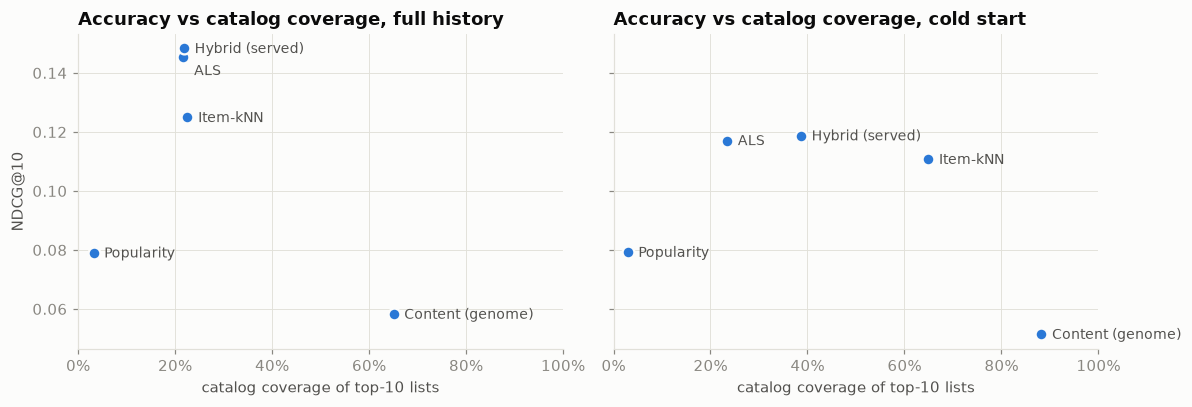

In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, setting in ((a, 'full history'), (b, 'cold start')):
    d = results[(results.setting == setting) & (results.model != 'Random')]
    ax.scatter(d.coverage, d['ndcg@10'], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    for _, r in d.iterrows():
        below = setting == 'full history' and r.model == 'ALS'  # sits just under the hybrid
        ax.annotate(r.model, (r.coverage, r['ndcg@10']), xytext=(7, -12 if below else -3),
                    textcoords='offset points', color=INK2, fontsize=9)
    ax.set(title=f'Accuracy vs catalog coverage, {setting}', xlabel='catalog coverage of top-10 lists',
           xlim=(0, 1))
    ax.xaxis.set_major_formatter('{x:.0%}')
a.set_ylabel('NDCG@10')
fig.tight_layout()
save(fig, 'accuracy_vs_coverage')

In the cold-start setting, ALS alone recommends from a narrow slice of the catalog because 3 likes give a weak
fold-in. The hybrid leans on the content model when history is short, with collaborative weight
`n / (n + history_prior)`. That raises coverage from 23% to 39% while keeping ALS-level accuracy.

### 2.2 The diversity trade-off

The served list is re-ranked with Maximal Marginal Relevance (MMR) on genome embeddings. The value λ was
chosen on **validation** with a stated rule: take the largest λ whose NDCG stays within 5% of no re-ranking. The test curve below
was computed only to report the result, not to choose λ.

The validation curve sits lower than the test curve because the folds differ. Validation models are fitted on the
training fold alone, and each user has only 10% of their history as targets. Test models are refit on train plus
validation, and each user has 20% as targets. Compare shapes, not absolute levels.

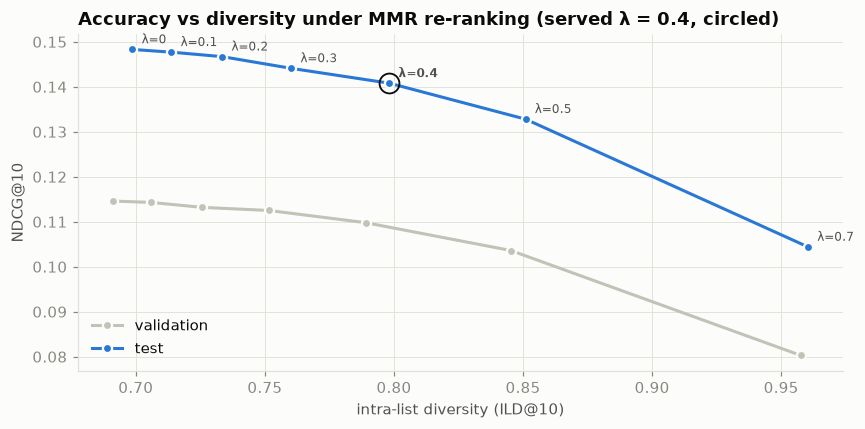

served λ=0.4: ILD 0.70 -> 0.80 (+14%), NDCG 0.1483 -> 0.1408 (-5.1%) on test


In [15]:
div = ev['diversity']
fig, ax = plt.subplots(figsize=(8, 4))
for split, color in (('validation', NEUTRAL), ('test', BLUE)):
    pts = pd.DataFrame(div[split])
    ax.plot(pts['ild@10'], pts['ndcg@10'], '-o', color=color, markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5, label=split)
test = pd.DataFrame(div['test'])
for _, r in test.iterrows():
    ax.annotate(f"λ={r.diversity:g}", (r['ild@10'], r['ndcg@10']), xytext=(6, 4), textcoords='offset points',
                fontsize=8, color=INK2, fontweight='bold' if r.diversity == div['selected'] else 'normal')
sel = test[test.diversity == div['selected']].iloc[0]
ax.plot(sel['ild@10'], sel['ndcg@10'], 'o', markersize=13, markerfacecolor='none', markeredgecolor=INK,
        markeredgewidth=1.2)
ax.set(xlabel='intra-list diversity (ILD@10)', ylabel='NDCG@10')
ax.set_title(f"Accuracy vs diversity under MMR re-ranking (served λ = {div['selected']:g}, circled)")
ax.legend(loc='lower left')
fig.tight_layout()
save(fig, 'diversity_tradeoff')

base = test.iloc[0]
print(f"served λ={div['selected']:g}: ILD {base['ild@10']:.2f} -> {sel['ild@10']:.2f} "
      f"(+{sel['ild@10'] / base['ild@10'] - 1:.0%}), NDCG {base['ndcg@10']:.4f} -> {sel['ndcg@10']:.4f} "
      f"({sel['ndcg@10'] / base['ndcg@10'] - 1:+.1%}) on test")

### 2.3 How ALS was tuned

A two-stage grid on validation. First factors × α at a fixed regularisation, then the regularisation at the best
(factors, α). The selected values are inside both grids, not at an edge, which guards against the optimum lying just
outside the searched range.

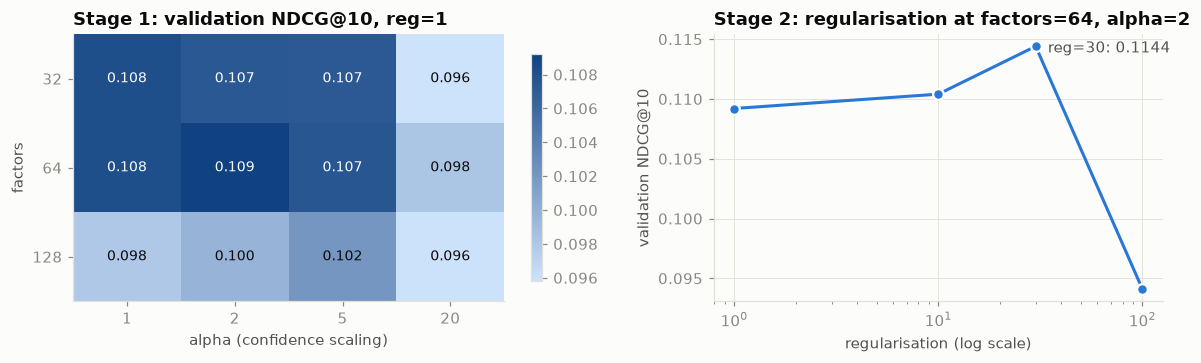

In [16]:
als = pd.DataFrame(ev['tuning']['als'])
stage1 = als[als.reg == als.reg.min()].pivot(index='factors', columns='alpha', values='ndcg@10')
best = ev['selected_params']['als']
stage2 = als[(als.factors == best['factors']) & (als.alpha == best['alpha'])].set_index('reg')['ndcg@10']

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.2, 1]})
im = a.imshow(stage1.to_numpy(), cmap=LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#104281']),
              aspect='auto')
a.set_xticks(range(stage1.shape[1]), [f'{x:g}' for x in stage1.columns])
a.set_yticks(range(stage1.shape[0]), stage1.index)
a.set(xlabel='alpha (confidence scaling)', ylabel='factors')
a.set_title(f'Stage 1: validation NDCG@10, reg={als.reg.min():g}')
a.grid(False)
vals = stage1.to_numpy()
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        a.text(j, i, f'{vals[i, j]:.3f}', ha='center', va='center', fontsize=9,
               color=SURFACE if vals[i, j] > np.median(vals) else INK)
fig.colorbar(im, ax=a, shrink=0.85)

b.plot(stage2.index, stage2.to_numpy(), '-o', color=BLUE, markersize=7, markeredgecolor=SURFACE,
       markeredgewidth=1.5)
b.set_xscale('log')
b.annotate(f"reg={stage2.idxmax():g}: {stage2.max():.4f}", (stage2.idxmax(), stage2.max()), xytext=(8, -4),
           textcoords='offset points', color=INK2)
b.set(xlabel='regularisation (log scale)', ylabel='validation NDCG@10')
b.set_title(f"Stage 2: regularisation at factors={best['factors']}, alpha={best['alpha']:g}")
fig.tight_layout()
save(fig, 'als_tuning')

### 2.4 Robustness

Two questions about all of the above. Does the ranking depend on *which* 10,000 users were sampled? And does it
survive a single global cut-off date, where nothing in training is newer than anything in test?
`python manage.py robustness_check` answers both with the hyperparameters already selected; it does not re-tune them.

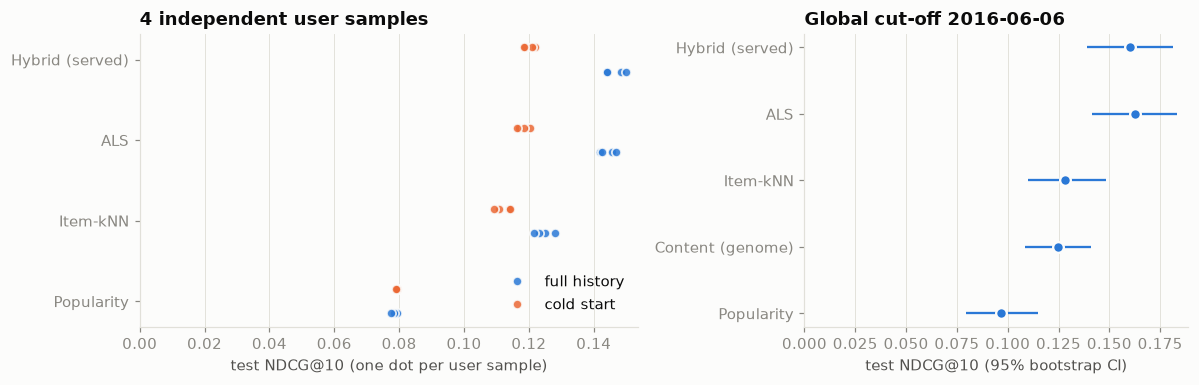

global split: 399 users evaluated, 1579 new after the cut-off; 18.5% of test likes are on movies with no likes before it


In [17]:
rob = json.loads((ROOT / 'reports' / 'robustness.json').read_text())
CORE = ['popularity', 'item_knn', 'als', 'hybrid']
samples = rob['resampled_users']['samples']

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.3, 1]})
y = np.arange(len(CORE))
for offset, (key, color, label) in zip((-0.15, 0.15), (('test_results', BLUE, 'full history'),
                                                     ('test_results_cold_start', ORANGE, 'cold start'))):
    for i, s in enumerate(samples.values()):
        a.plot([s[key][m]['ndcg@10'] for m in CORE], y + offset, 'o', color=color, markersize=6,
               markeredgecolor=SURFACE, markeredgewidth=1.2, alpha=0.85, label=label if i == 0 else None)
a.set_yticks(y, [LABELS[m] for m in CORE])
a.grid(axis='y', visible=False)
a.set(xlabel='test NDCG@10 (one dot per user sample)', xlim=(0, None))
a.set_title(f'{len(samples)} independent user samples')
a.legend(loc='lower right')

g = rob['global_time_split']['test_results']
d = pd.DataFrame({m: g[m] for m in MODELS[1:]}).T
yy = np.arange(len(d))
b.errorbar(d['ndcg@10'], yy, xerr=[d['ndcg@10'] - d['ndcg@10_ci95'].str[0], d['ndcg@10_ci95'].str[1] - d['ndcg@10']],
           fmt='o', color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, elinewidth=1.5)
b.set_yticks(yy, [LABELS[m] for m in d.index])
b.grid(axis='y', visible=False)
b.set(xlabel='test NDCG@10 (95% bootstrap CI)', xlim=(0, None))
b.set_title(f"Global cut-off {rob['global_time_split']['cutoff_date']}")
fig.tight_layout()
save(fig, 'robustness')

gs = rob['global_time_split']
print(f"global split: {gs['users']['evaluated']} users evaluated, {gs['users']['new_after_cutoff']} new after the "
      f"cut-off; {gs['test_likes_on_items_without_training_likes']:.1%} of test likes are on movies with no likes "
      'before it')

**Reading it.** The user-sample spread is small compared with the gaps between models, and the order is the same in
every sample. Under the global cut-off ALS still clearly beats item-kNN, and the hybrid ties ALS. Content-only
recommendations jump ahead of popularity there, because almost a fifth of the test likes go to movies that nobody in the
sample had liked before the cut-off: collaborative filtering has no signal for those yet, but the Tag Genome does. That points
to the next modelling step: let the blend also depend on how new an item is, not only on how long the user's history is.

## 3. Takeaways and caveats

- **Data.** A seeded sample of 10,000 users and the 5,000 most-rated movies keeps 92% of the rating mass. Every
  stage then runs in under 0.5 GB of RAM: the full pipeline needs about 85 s to prepare the data and about 6 min to
  evaluate. Nothing builds a dense user×item or item×item matrix.
- **Models.** ALS is the strongest single model. The hybrid adds content similarity, weighted by history length,
  which gives a small accuracy gain and much better catalog coverage for new users. MMR adds diversity
  at a known, pre-registered cost.
- **Caveats.**
  - The Tag Genome and the catalog selection were computed by GroupLens from *all* ratings, including the
    test period, so a little future information leaks into the side features.
  - The main split is per user, so one user's test period can come before another user's training data. The global
    cut-off in section 2.4 removes this, and the main conclusions hold, but only about 400 users can be evaluated
    that way.
  - Hyperparameters were tuned once, on the main sample, and reused in the robustness checks.
  - All of this is offline evaluation. The app logs impressions and actions so that it can measure the online
    action rate (`/analytics/`).